# Stage 1 单变量扫描结果可视化

数据源：`loss_weight_compare.py` 导出的数值版 CSV（`loss_weight_search_results_numeric.csv`）。

每个子图对应一个 sweep（固定另外 3 个权重 = 默认值，只变 1 个），展示 7 个测试集指标随该权重值的变化曲线。
分别对 `cross_day` 和 `cross_subject` 两种 split 画图。

In [5]:
# ========= 配置：改这里换数据源 =========
CSV_PATH = "/root/zjm/cadt_test_code/report/07.loss_weight_search_results_numeric.csv"
# ======================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
})

df = pd.read_csv(CSV_PATH)
print(f"Loaded {len(df)} rows from {CSV_PATH}")
print("sweep_type × split_mode distribution:")
print(pd.crosstab(df["sweep_type"], df["split_mode"]).to_string())
df.head()

Loaded 40 rows from /root/zjm/cadt_test_code/report/07.loss_weight_search_results_numeric.csv
sweep_type × split_mode distribution:
split_mode                 cross_day  cross_subject  within_subject_day
sweep_type                                                             
baseline                           1              1                   1
contrast_tau                       3              3                   0
discriminator_loss_weight          5              5                   0
domain_cls_weight                  5              5                   0
sphere_loss_weight                 5              5                   1


,sphere_loss_weight,discriminator_loss_weight,domain_cls_weight,contrast_tau,split_mode,n_seeds,Test MSE_mean,Test MAE_mean,Test RMSE_mean,Test R2_mean,Test Avg R2 (per-dim)_mean,Test Pearson_mean,Test Spearman_mean,Val R2_mean,Val Pearson_mean,Val Spearman_mean,sweep_type
0,1.0,1.0,1.0,1.0,cross_subject,1,0.700158,0.692188,0.836755,0.107507,-0.178610,0.013451,-0.023386,0.199207,-0.027011,-0.072678,sphere_loss_weight
1,1.0,1.0,1.0,1.0,cross_day,1,0.834975,0.722324,0.913769,0.184082,-0.005116,0.188045,0.220729,0.226753,-0.013901,0.036565,sphere_loss_weight
2,5.0,1.0,1.0,1.0,cross_subject,1,0.743408,0.714233,0.862211,0.052377,-0.254495,0.025606,-0.037912,0.212765,-0.061913,-0.103964,sphere_loss_weight
3,5.0,1.0,1.0,1.0,cross_day,1,0.835606,0.721527,0.914115,0.183465,-0.005263,0.105429,0.116071,0.226513,-0.006562,0.027785,sphere_loss_weight
4,10.0,1.0,1.0,1.0,cross_day,1,0.838359,0.722351,0.915620,0.180774,-0.009398,0.175216,0.206892,0.225018,-0.010194,0.002955,baseline


## cross_day：4 张子图

- **x 轴**：变化的那个权重值（含 baseline 默认值）
- **y 轴**：测试集指标数值
- 7 条曲线分别是 MSE / R2 / Avg R2 / Pearson / Spearman / MAE / RMSE

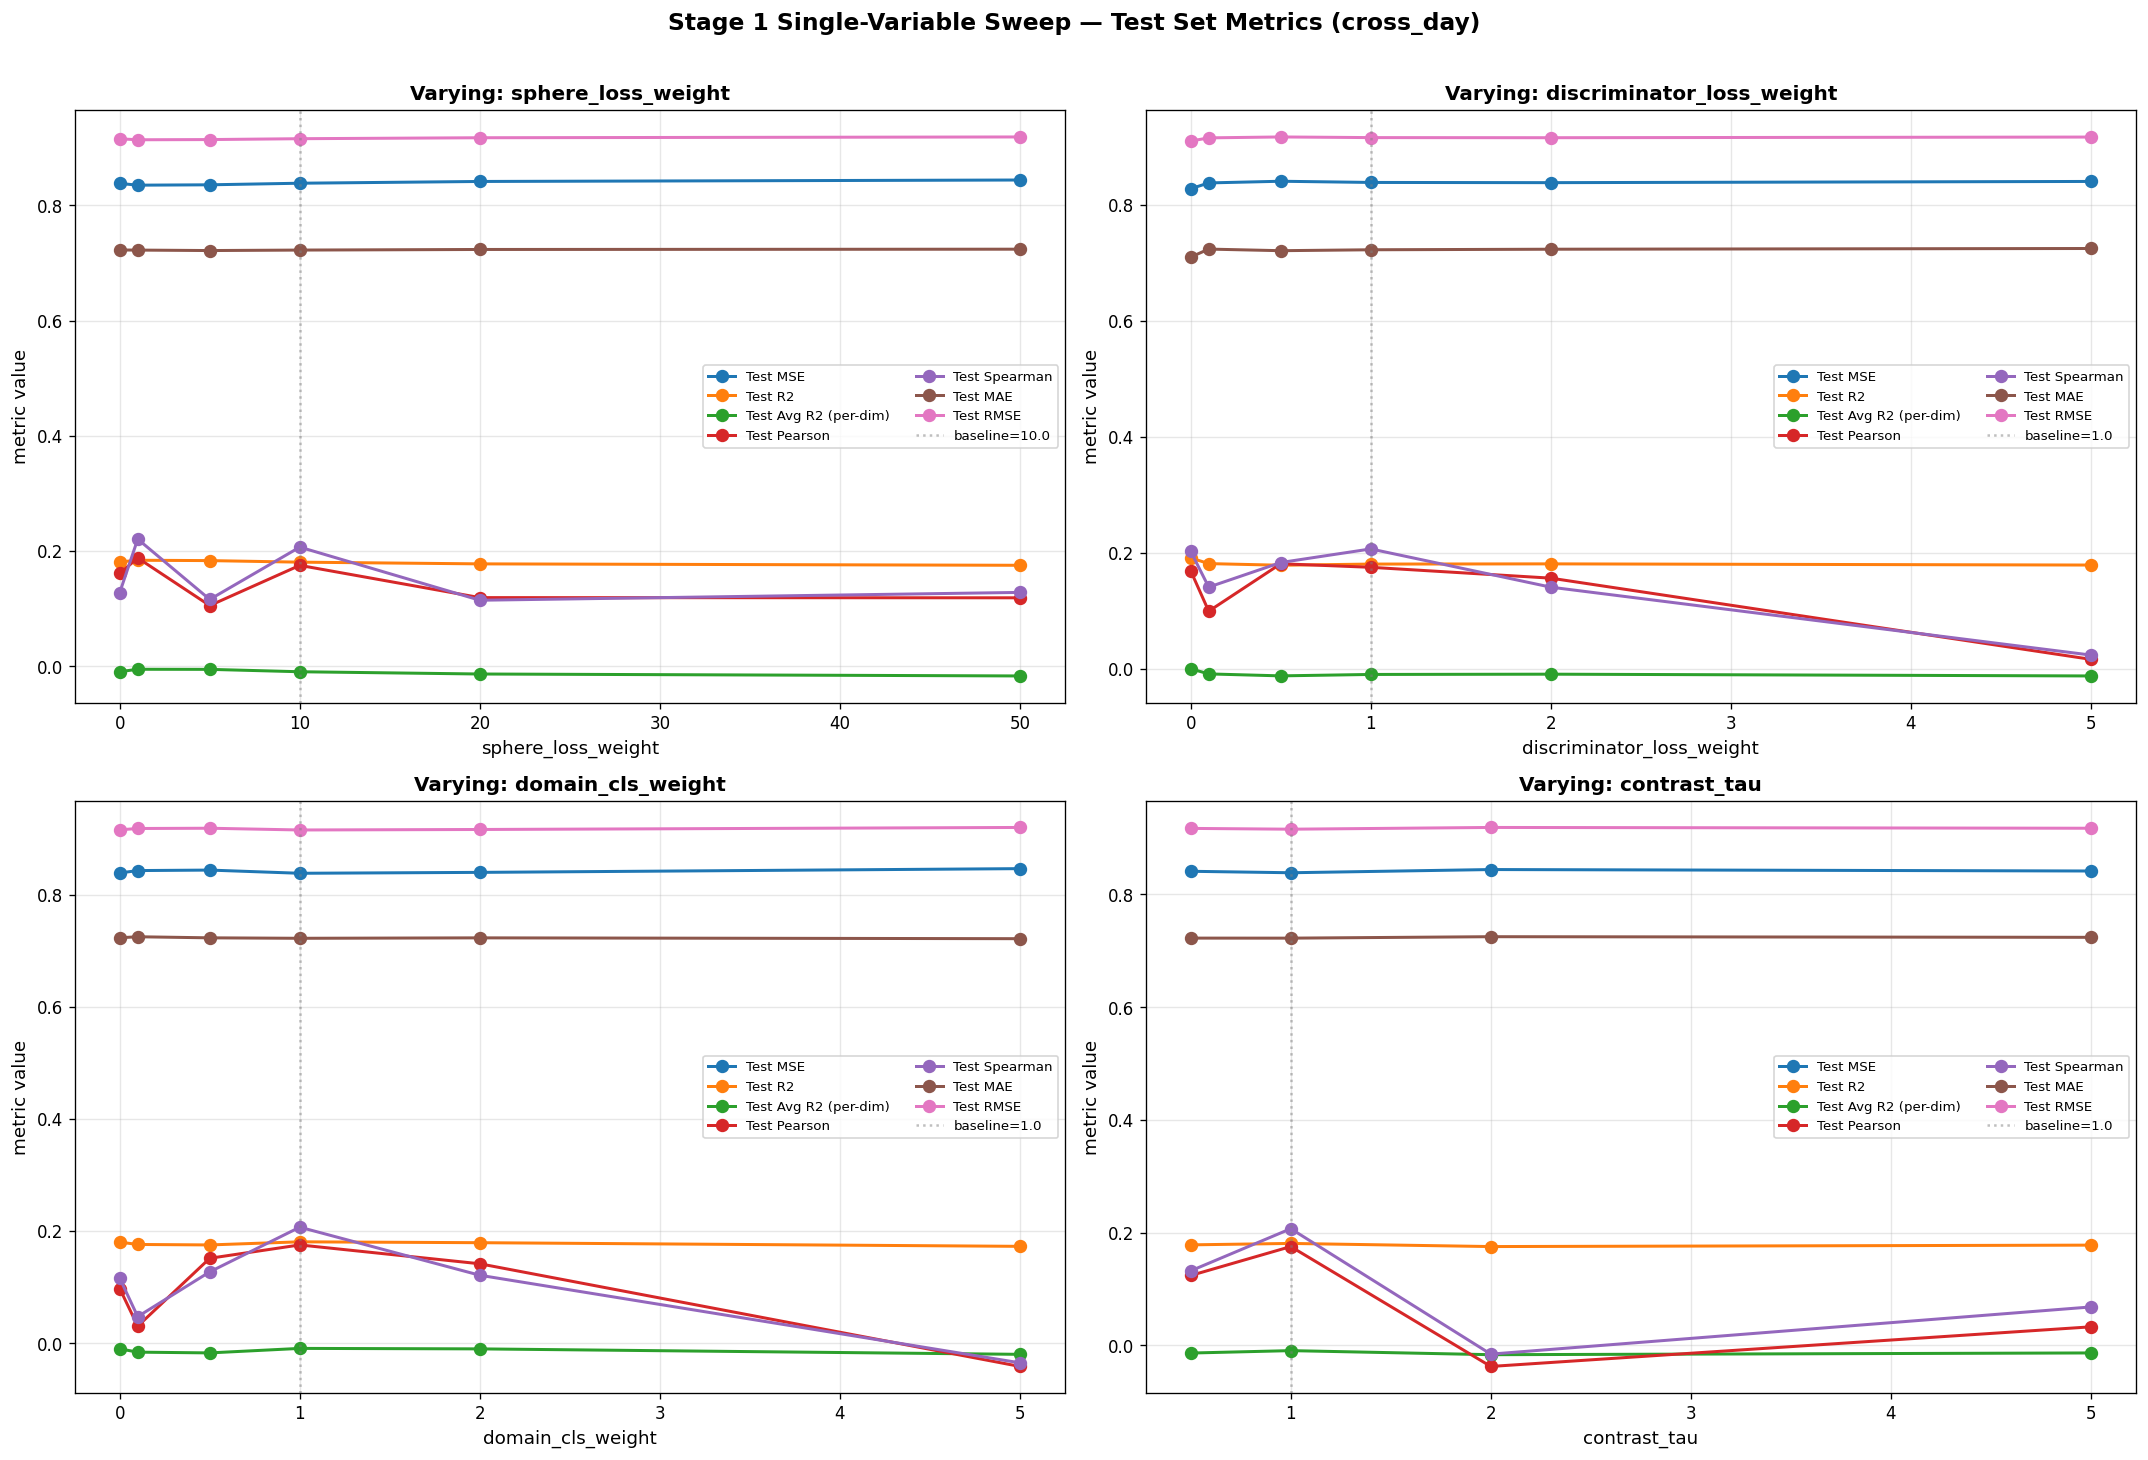

In [6]:
SWEEPS = [
    ("sphere_loss_weight",        "sphere_loss_weight",        "sphere_loss_weight"),
    ("discriminator_loss_weight", "discriminator_loss_weight", "discriminator_loss_weight"),
    ("domain_cls_weight",         "domain_cls_weight",         "domain_cls_weight"),
    ("contrast_tau",              "contrast_tau",              "contrast_tau"),
]
METRICS = ["Test MSE", "Test R2", "Test Avg R2 (per-dim)",
           "Test Pearson", "Test Spearman", "Test MAE", "Test RMSE"]
COLORS = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2"]
DEFAULTS = {"sphere_loss_weight":10.0, "discriminator_loss_weight":1.0,
            "domain_cls_weight":1.0, "contrast_tau":1.0}

def plot_split(df, split, figsize=(18, 12)):
    fig, axes = plt.subplots(2, 2, figsize=figsize)
    axes = axes.flatten()
    dfs = df[df["split_mode"] == split]
    for ax, (sweep_type, wk, title) in zip(axes, SWEEPS):
        sub = dfs[dfs["sweep_type"].isin([sweep_type, "baseline"])].copy()
        sub = sub.sort_values(wk).reset_index(drop=True)
        x = sub[wk].values
        for i, m in enumerate(METRICS):
            col = f"{m}_mean"
            if col not in sub.columns: continue
            y = sub[col].values
            ax.plot(x, y, marker="o", linestyle="-", color=COLORS[i],
                    label=m, linewidth=1.8, markersize=7)
        if wk in DEFAULTS:
            ax.axvline(DEFAULTS[wk], color="gray", linestyle=":",
                       alpha=0.5, label=f"baseline={DEFAULTS[wk]}")
        ax.set_xlabel(wk, fontsize=11)
        ax.set_ylabel("metric value", fontsize=11)
        ax.set_title(f"Varying: {title}", fontsize=12, fontweight="bold")
        ax.legend(fontsize=8, loc="best", ncol=2)
    fig.suptitle(f"Stage 1 Single-Variable Sweep — Test Set Metrics ({split})",
                 fontsize=14, fontweight="bold", y=1.01)
    fig.tight_layout()
    return fig, axes

fig, _ = plot_split(df, "cross_day")
plt.savefig("/root/zjm/cadt_test_code/report/07.stage1_sweep_cross_day.png", dpi=150, bbox_inches="tight")
plt.show()

## cross_subject：4 张子图

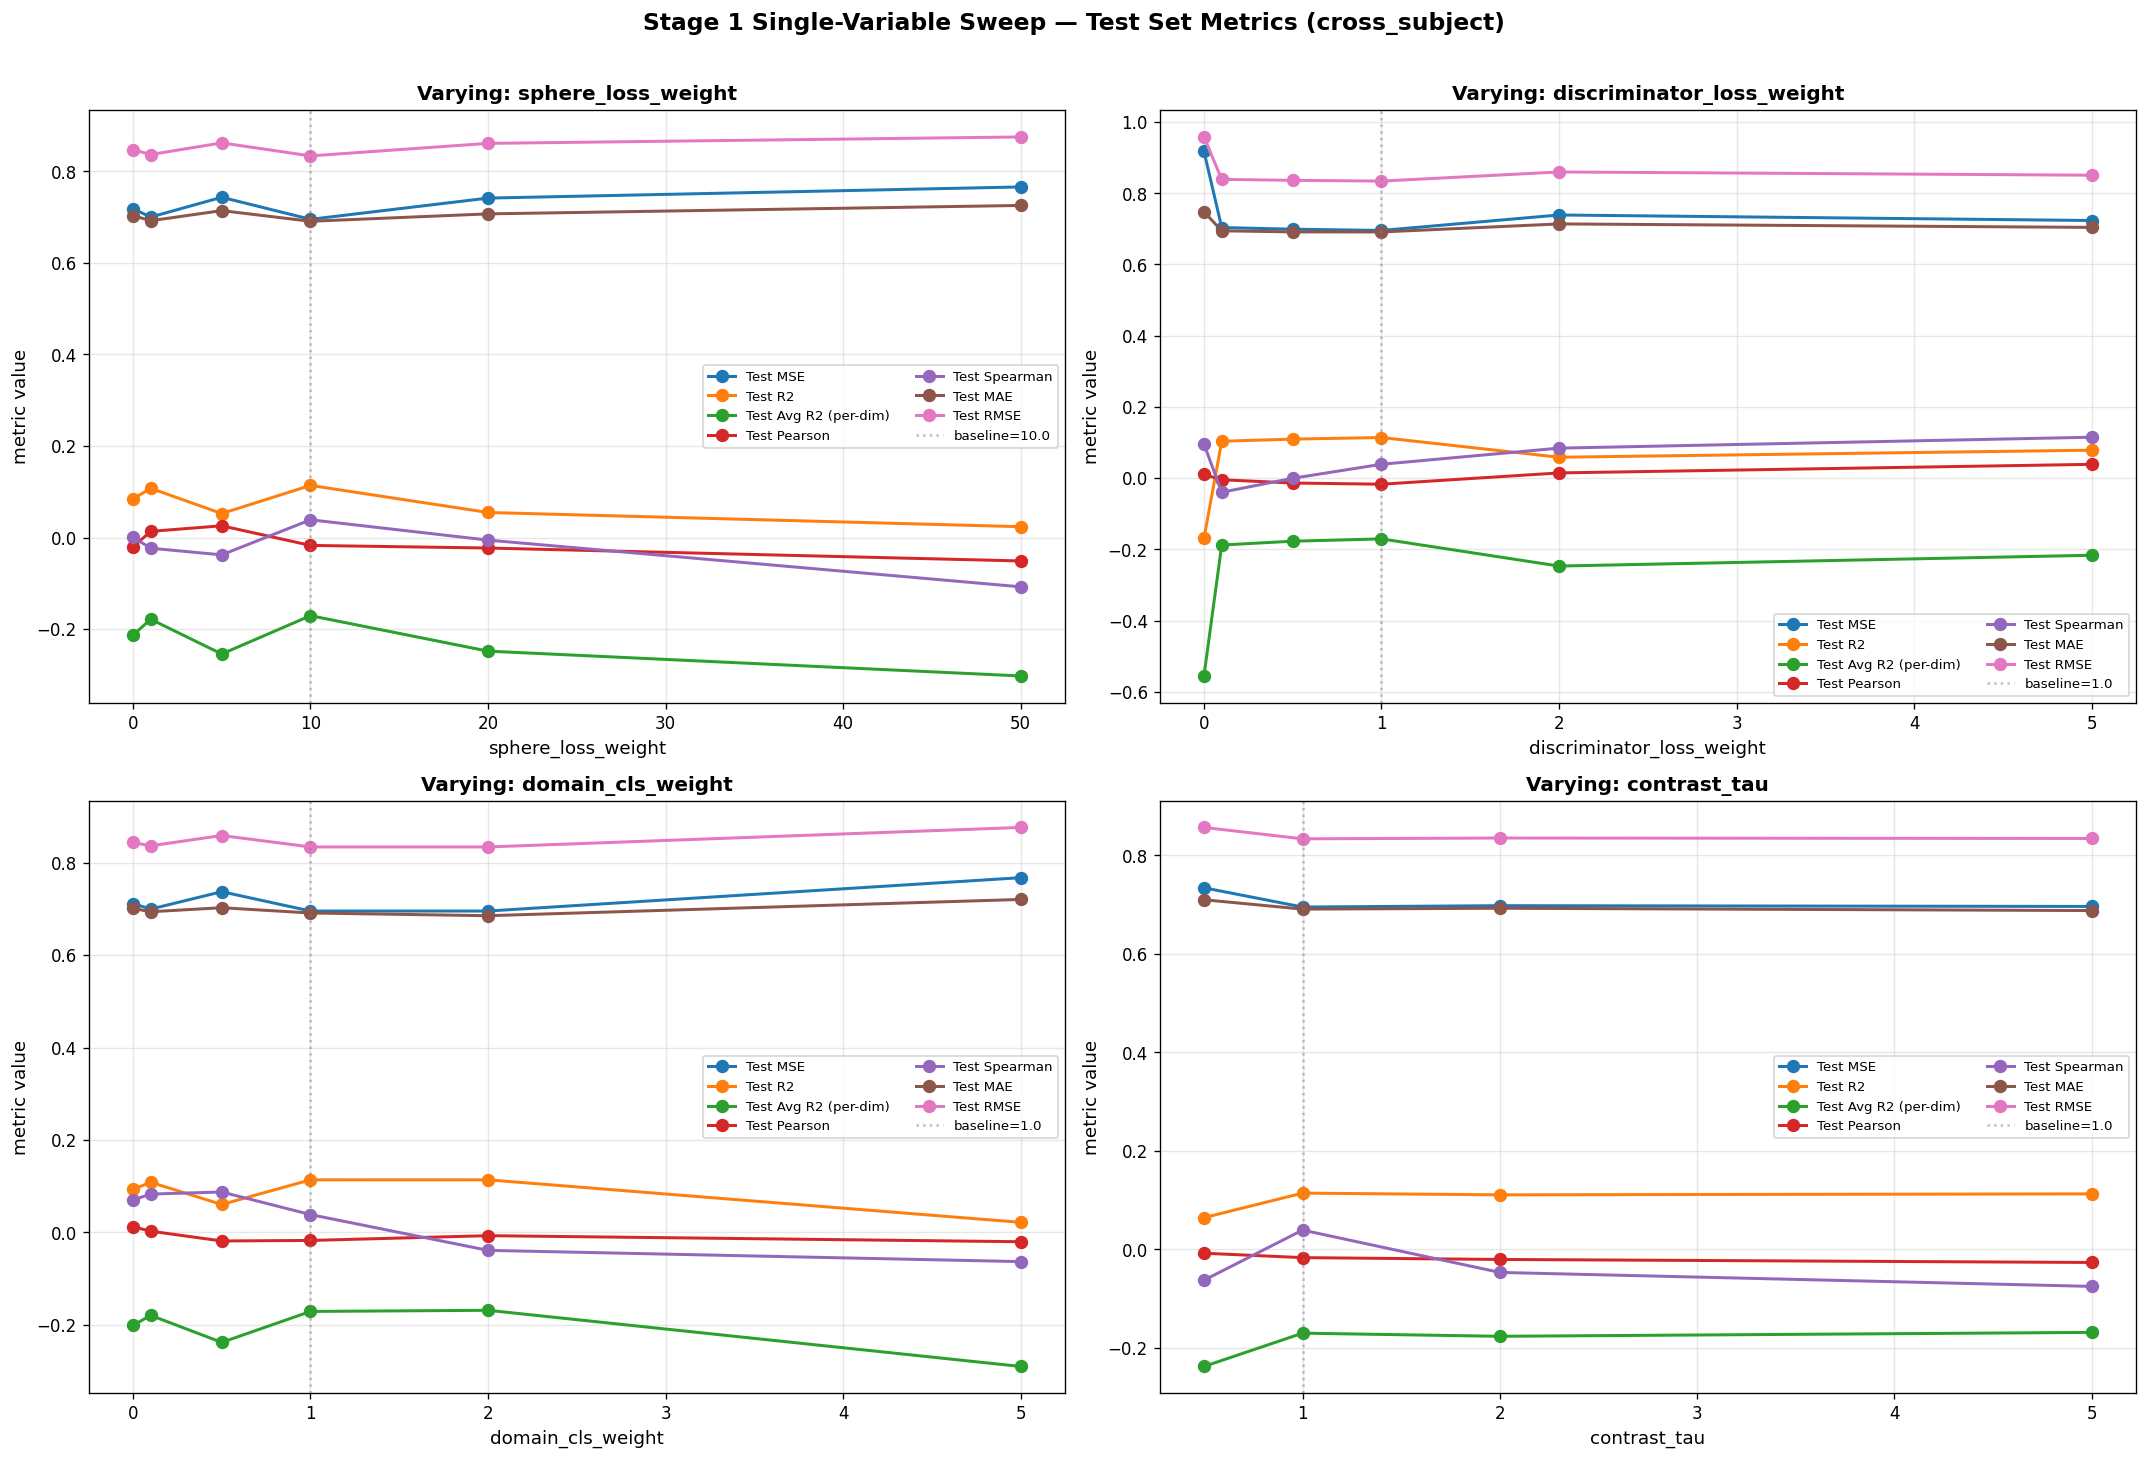

In [7]:
fig, _ = plot_split(df, "cross_subject")
plt.savefig("/root/zjm/cadt_test_code/report/07.stage1_sweep_cross_subject.png", dpi=150, bbox_inches="tight")
plt.show()

## 各 sweep 的数值表（便于选最优值）

In [8]:
for split in ["cross_day", "cross_subject"]:
    dfs = df[df["split_mode"] == split]
    print(f"\n{'#'*80}")
    print(f"  split_mode = {split}")
    print(f"{'#'*80}")
    for sweep_type, wk, title in SWEEPS:
        sub = dfs[dfs["sweep_type"].isin([sweep_type, "baseline"])].copy().sort_values(wk)
        cols = [wk, "n_seeds"] + [f"{m}_mean" for m in METRICS if f"{m}_mean" in sub.columns]
        print(f"\n  Varying: {title}  ({len(sub)} runs)")
        print(sub[cols].round(4).to_string(index=False))


################################################################################
  split_mode = cross_day
################################################################################

  Varying: sphere_loss_weight  (6 runs)
 sphere_loss_weight  n_seeds  Test MSE_mean  Test R2_mean  Test Avg R2 (per-dim)_mean  Test Pearson_mean  Test Spearman_mean  Test MAE_mean  Test RMSE_mean
                0.0        1         0.8380        0.1811                     -0.0093             0.1611              0.1279         0.7225          0.9154
                1.0        1         0.8350        0.1841                     -0.0051             0.1880              0.2207         0.7223          0.9138
                5.0        1         0.8356        0.1835                     -0.0053             0.1054              0.1161         0.7215          0.9141
               10.0        1         0.8384        0.1808                     -0.0094             0.1752              0.2069         0.7224        